<a href="https://colab.research.google.com/github/Subramanya135raikar/AI-Smart-Waste-Sorting/blob/main/Waste_Sorting_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Hello Collab")

Hello Collab


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

PROJECT_NAME = "AI_Smart_Waste_Sorting"

CLASSES= ["Plastic", "Paper", "Metal"]

IMAGE_SIZE = (128,128)
BATCH_SIZE = 32
EPOCHS = 10

for folder in["dataset", "models", "results"]:
  os.makedirs(folder, exist_ok=True)

print("Project:", PROJECT_NAME)
print("Waste Categories:", CLASSES)
print("Image Size:", IMAGE_SIZE)
print("TensorFlow Version:", tf.__version__)
print("Project folders created successfully")

Project: AI_Smart_Waste_Sorting
Waste Categories: ['Plastic', 'Paper', 'Metal']
Image Size: (128, 128)
TensorFlow Version: 2.20.0
Project folders created successfully


In [7]:
import os
from google.colab import files

# Our dataset folders
CLASSES = ["Plastic", "Paper", "Metal"]

# Select a category
category = input("Enter category (Plastic, Paper, Metal): ").strip().capitalize()

if category not in CLASSES:
    print("Invalid category. Please try again.")
else:
    folder = os.path.join("dataset", category)
    os.makedirs(folder, exist_ok=True)

    print(f"Upload images for {category}:")
    uploaded = files.upload()

    count = 0

    for filename, content in uploaded.items():
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            save_path = os.path.join(
                folder, f"{category}_{len(os.listdir(folder)) + 1}_{os.path.basename(filename)}"
            )

            with open(save_path, "wb") as f:
                f.write(content)

            count += 1

    print(f"{count} images saved in {folder}")

Enter category (Plastic, Paper, Metal): metal
Upload images for Metal:


Saving images (9).jpeg to images (9).jpeg
Saving images (10).jpeg to images (10).jpeg
Saving images (11).jpeg to images (11).jpeg
Saving images (12).jpeg to images (12).jpeg
Saving images (13).jpeg to images (13).jpeg
5 images saved in dataset/Metal


In [8]:
import os
from PIL import Image
import matplotlib.pyplot as plt

# Our dataset categories
CLASSES = ["Plastic", "Paper", "Metal"]
DATASET_PATH = "dataset"

# Count and validate images
valid_images = {}

for category in CLASSES:
    folder = os.path.join(DATASET_PATH, category)
    valid_images[category] = []

    if not os.path.exists(folder):
        print(f"❌ Folder missing: {category}")
        continue

    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)

        try:
            with Image.open(path) as img:
                img.verify()
            valid_images[category].append(path)
        except Exception:
            print(f"⚠️ Could not read: {filename}")

    print(f"✅ {category}: {len(valid_images[category])} valid images")

print("\nDataset verification complete!")

✅ Plastic: 5 valid images
✅ Paper: 5 valid images
✅ Metal: 5 valid images

Dataset verification complete!


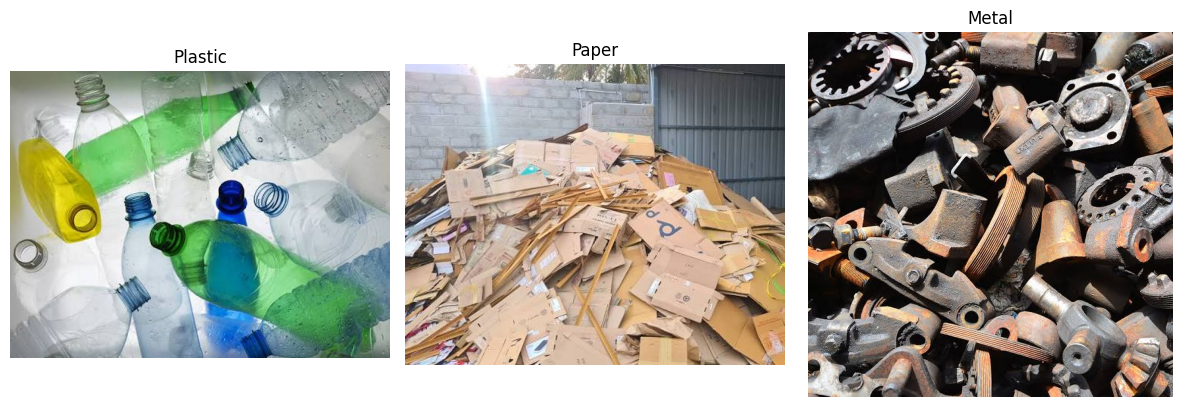

In [9]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, category in zip(axes, CLASSES):
    images = valid_images[category]

    if images:
        img = Image.open(images[0]).convert("RGB")
        ax.imshow(img)
        ax.set_title(category)
    else:
        ax.set_title(f"{category}: No images")

    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
import numpy as np
from PIL import Image
import os

# Image configuration
IMAGE_SIZE = (128, 128)
CLASSES = ["Plastic", "Paper", "Metal"]

# Prepare image data
X = []
y = []

for label, category in enumerate(CLASSES):
    for path in valid_images[category]:
        try:
            # Open and resize image
            img = Image.open(path).convert("RGB")
            img = img.resize(IMAGE_SIZE)

            # Convert image to numerical array
            img_array = np.array(img, dtype=np.float32) / 255.0

            X.append(img_array)
            y.append(label)

        except Exception as e:
            print(f"Error processing {path}: {e}")

# Convert lists into NumPy arrays
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

print("Image preparation complete!")
print("Image data shape:", X.shape)
print("Labels shape:", y.shape)
print("Categories:", CLASSES)

Image preparation complete!
Image data shape: (15, 128, 128, 3)
Labels shape: (15,)
Categories: ['Plastic', 'Paper', 'Metal']


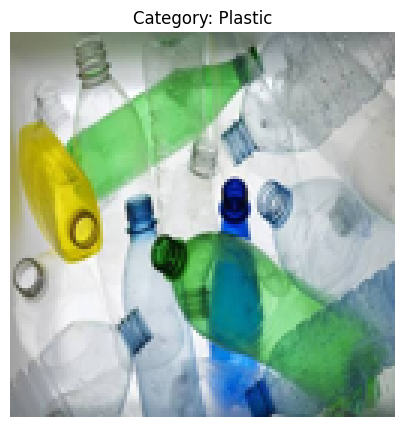

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))

plt.imshow(X[0])
plt.title(f"Category: {CLASSES[y[0]]}")
plt.axis("off")

plt.show()

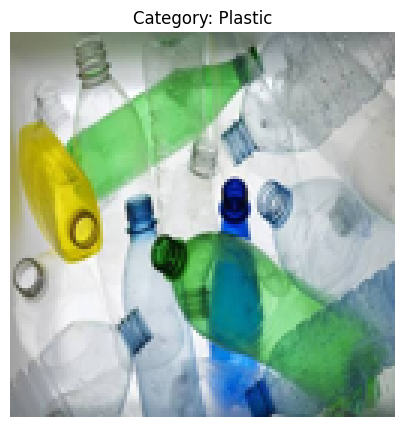

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))

plt.imshow(X[0])
plt.title(f"Category: {CLASSES[y[0]]}")
plt.axis("off")

plt.show()

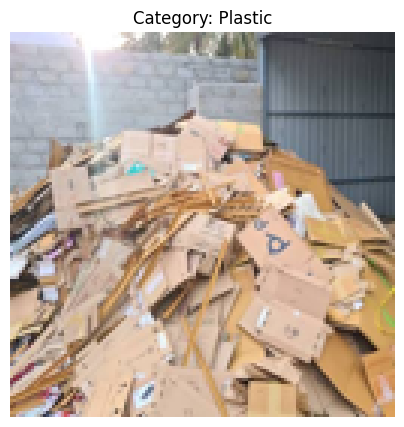

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))

plt.imshow(X[5])
plt.title(f"Category: {CLASSES[y[0]]}")
plt.axis("off")

plt.show()

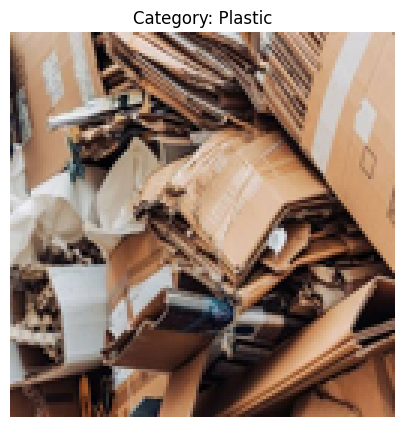

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))

plt.imshow(X[6
            ])
plt.title(f"Category: {CLASSES[y[0]]}")
plt.axis("off")

plt.show()

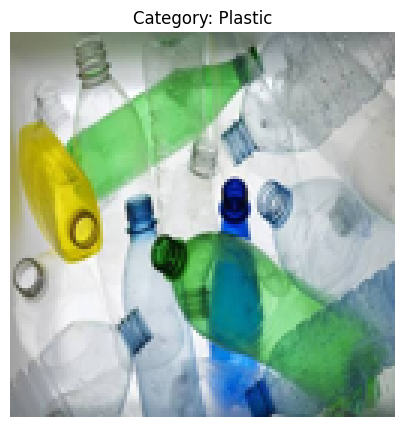

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))

plt.imshow(X[0])
plt.title(f"Category: {CLASSES[y[1]]}")
plt.axis("off")

plt.show()

In [16]:
print("Total images:", len(X))
print("Labels:", y)

for i in range(len(y)):
    print(i, "->", CLASSES[y[i]])

Total images: 15
Labels: [0 0 0 0 0 1 1 1 1 1 2 2 2 2 2]
0 -> Plastic
1 -> Plastic
2 -> Plastic
3 -> Plastic
4 -> Plastic
5 -> Paper
6 -> Paper
7 -> Paper
8 -> Paper
9 -> Paper
10 -> Metal
11 -> Metal
12 -> Metal
13 -> Metal
14 -> Metal


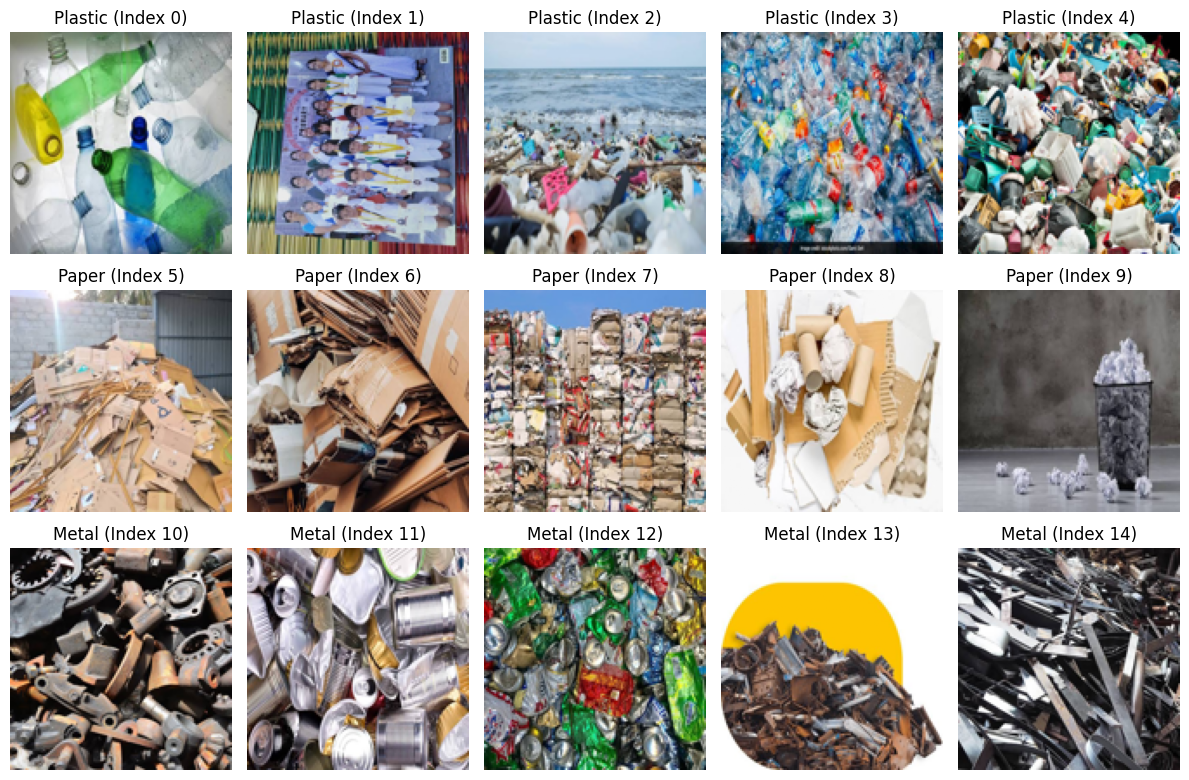

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i in range(len(X)):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X[i])
    plt.title(f"{CLASSES[y[i]]} (Index {i})")
    plt.axis("off")

plt.tight_layout()
plt.show()0

In [18]:
# Build a CNN model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    # First convolutional layer
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second convolutional layer
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Third convolutional layer
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Flatten and classify
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
history = model.fit(

                    X,
                    y,
                    epochs=10,
                    batch_size=4,
                    verbose=1
)

Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 173ms/step - accuracy: 0.2000 - loss: 2.0938
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 191ms/step - accuracy: 0.4000 - loss: 1.0613
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 176ms/step - accuracy: 0.3333 - loss: 1.1823
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 180ms/step - accuracy: 0.6667 - loss: 1.0156
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 172ms/step - accuracy: 0.4667 - loss: 1.0503
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 170ms/step - accuracy: 0.4667 - loss: 1.1399
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 178ms/step - accuracy: 0.3333 - loss: 1.0691
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 285ms/step - accuracy: 0.4667 - loss: 0.9771
Epoch 9/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 270ms/step - accuracy: 0.4667 - loss: 0.9504
Epoch 10/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 241ms/step - accuracy: 0.8000 - loss: 0.7932


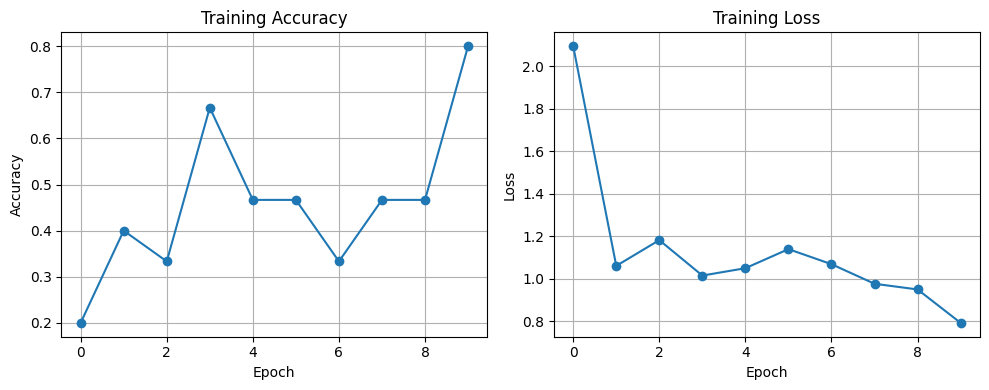

In [21]:
import matplotlib.pyplot as plt

# Plot training accuracy
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], marker='o')
plt.title('Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True)

# Plot training loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], marker='o')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)

plt.tight_layout()
plt.show()

In [22]:
model.save("waste_sorting_model.keras")